<a href="https://colab.research.google.com/github/Ash-Amarnath/EMJM_Assignments/blob/main/Python_A2B_Ash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

# ==========================================================
# PART 1: Data Loading & Audit
# ==========================================================
file_path = '/content/drive/MyDrive/spike_data_zip.npz'
data = np.load(file_path)

# Extract core arrays
t = data['t']
raw_data = data['raw_data']

# Derive dynamic sampling properties
dt = t[1] - t[0]
fs = 1.0 / dt
duration = t[-1] - t[0]

# Construct Data Audit DataFrame
audit_df = pd.DataFrame({
    'Property': [
        'Number of samples (t)',
        'Number of samples (raw_data)',
        'Array shape (t)',
        'Array shape (raw_data)',
        'Data type (t)',
        'Data type (raw_data)',
        'Sampling interval (dt)',
        'Inferred sampling frequency (fs)',
        'Nominal recording duration'
    ],
    'Your result': [
        len(t),
        len(raw_data),
        str(t.shape),
        str(raw_data.shape),
        str(t.dtype),
        str(raw_data.dtype),
        f"{dt:.6f} seconds",
        f"{fs:.2f} Hz",
        f"{duration:.2f} seconds"
    ]
})

print("=== PART 1: DATA AUDIT TABLE ===")
display(audit_df)

# Sanity check for data integrity
print(f"Missing (NaN) values in t:        {np.isnan(t).sum()}")
print(f"Infinite values in t:             {np.isinf(t).sum()}")
print(f"Missing (NaN) values in raw_data: {np.isnan(raw_data).sum()}")
print(f"Infinite values in raw_data:      {np.isinf(raw_data).sum()}")

=== PART 1: DATA AUDIT TABLE ===


,Property,Your result
0,Number of samples (t),10000
1,Number of samples (raw_data),10000
2,Array shape (t),"(10000,)"
3,Array shape (raw_data),"(10000,)"
4,Data type (t),float64
5,Data type (raw_data),float64
6,Sampling interval (dt),0.001000 seconds
7,Inferred sampling frequency (fs),1000.00 Hz
8,Nominal recording duration,10.00 seconds


Missing (NaN) values in t:        0
Infinite values in t:             0
Missing (NaN) values in raw_data: 0
Infinite values in raw_data:      0


=== PART 2: SIGNAL NUMERICAL SUMMARY ===


,Metric,Raw Signal,Baseline-Corrected
0,Minimum,-1.690989,-1.101951
1,Maximum,6.201963,5.532628
2,Mean,0.076882,0.055327
3,Median,0.035412,0.000000
4,Standard Deviation (SD),0.734406,0.543695


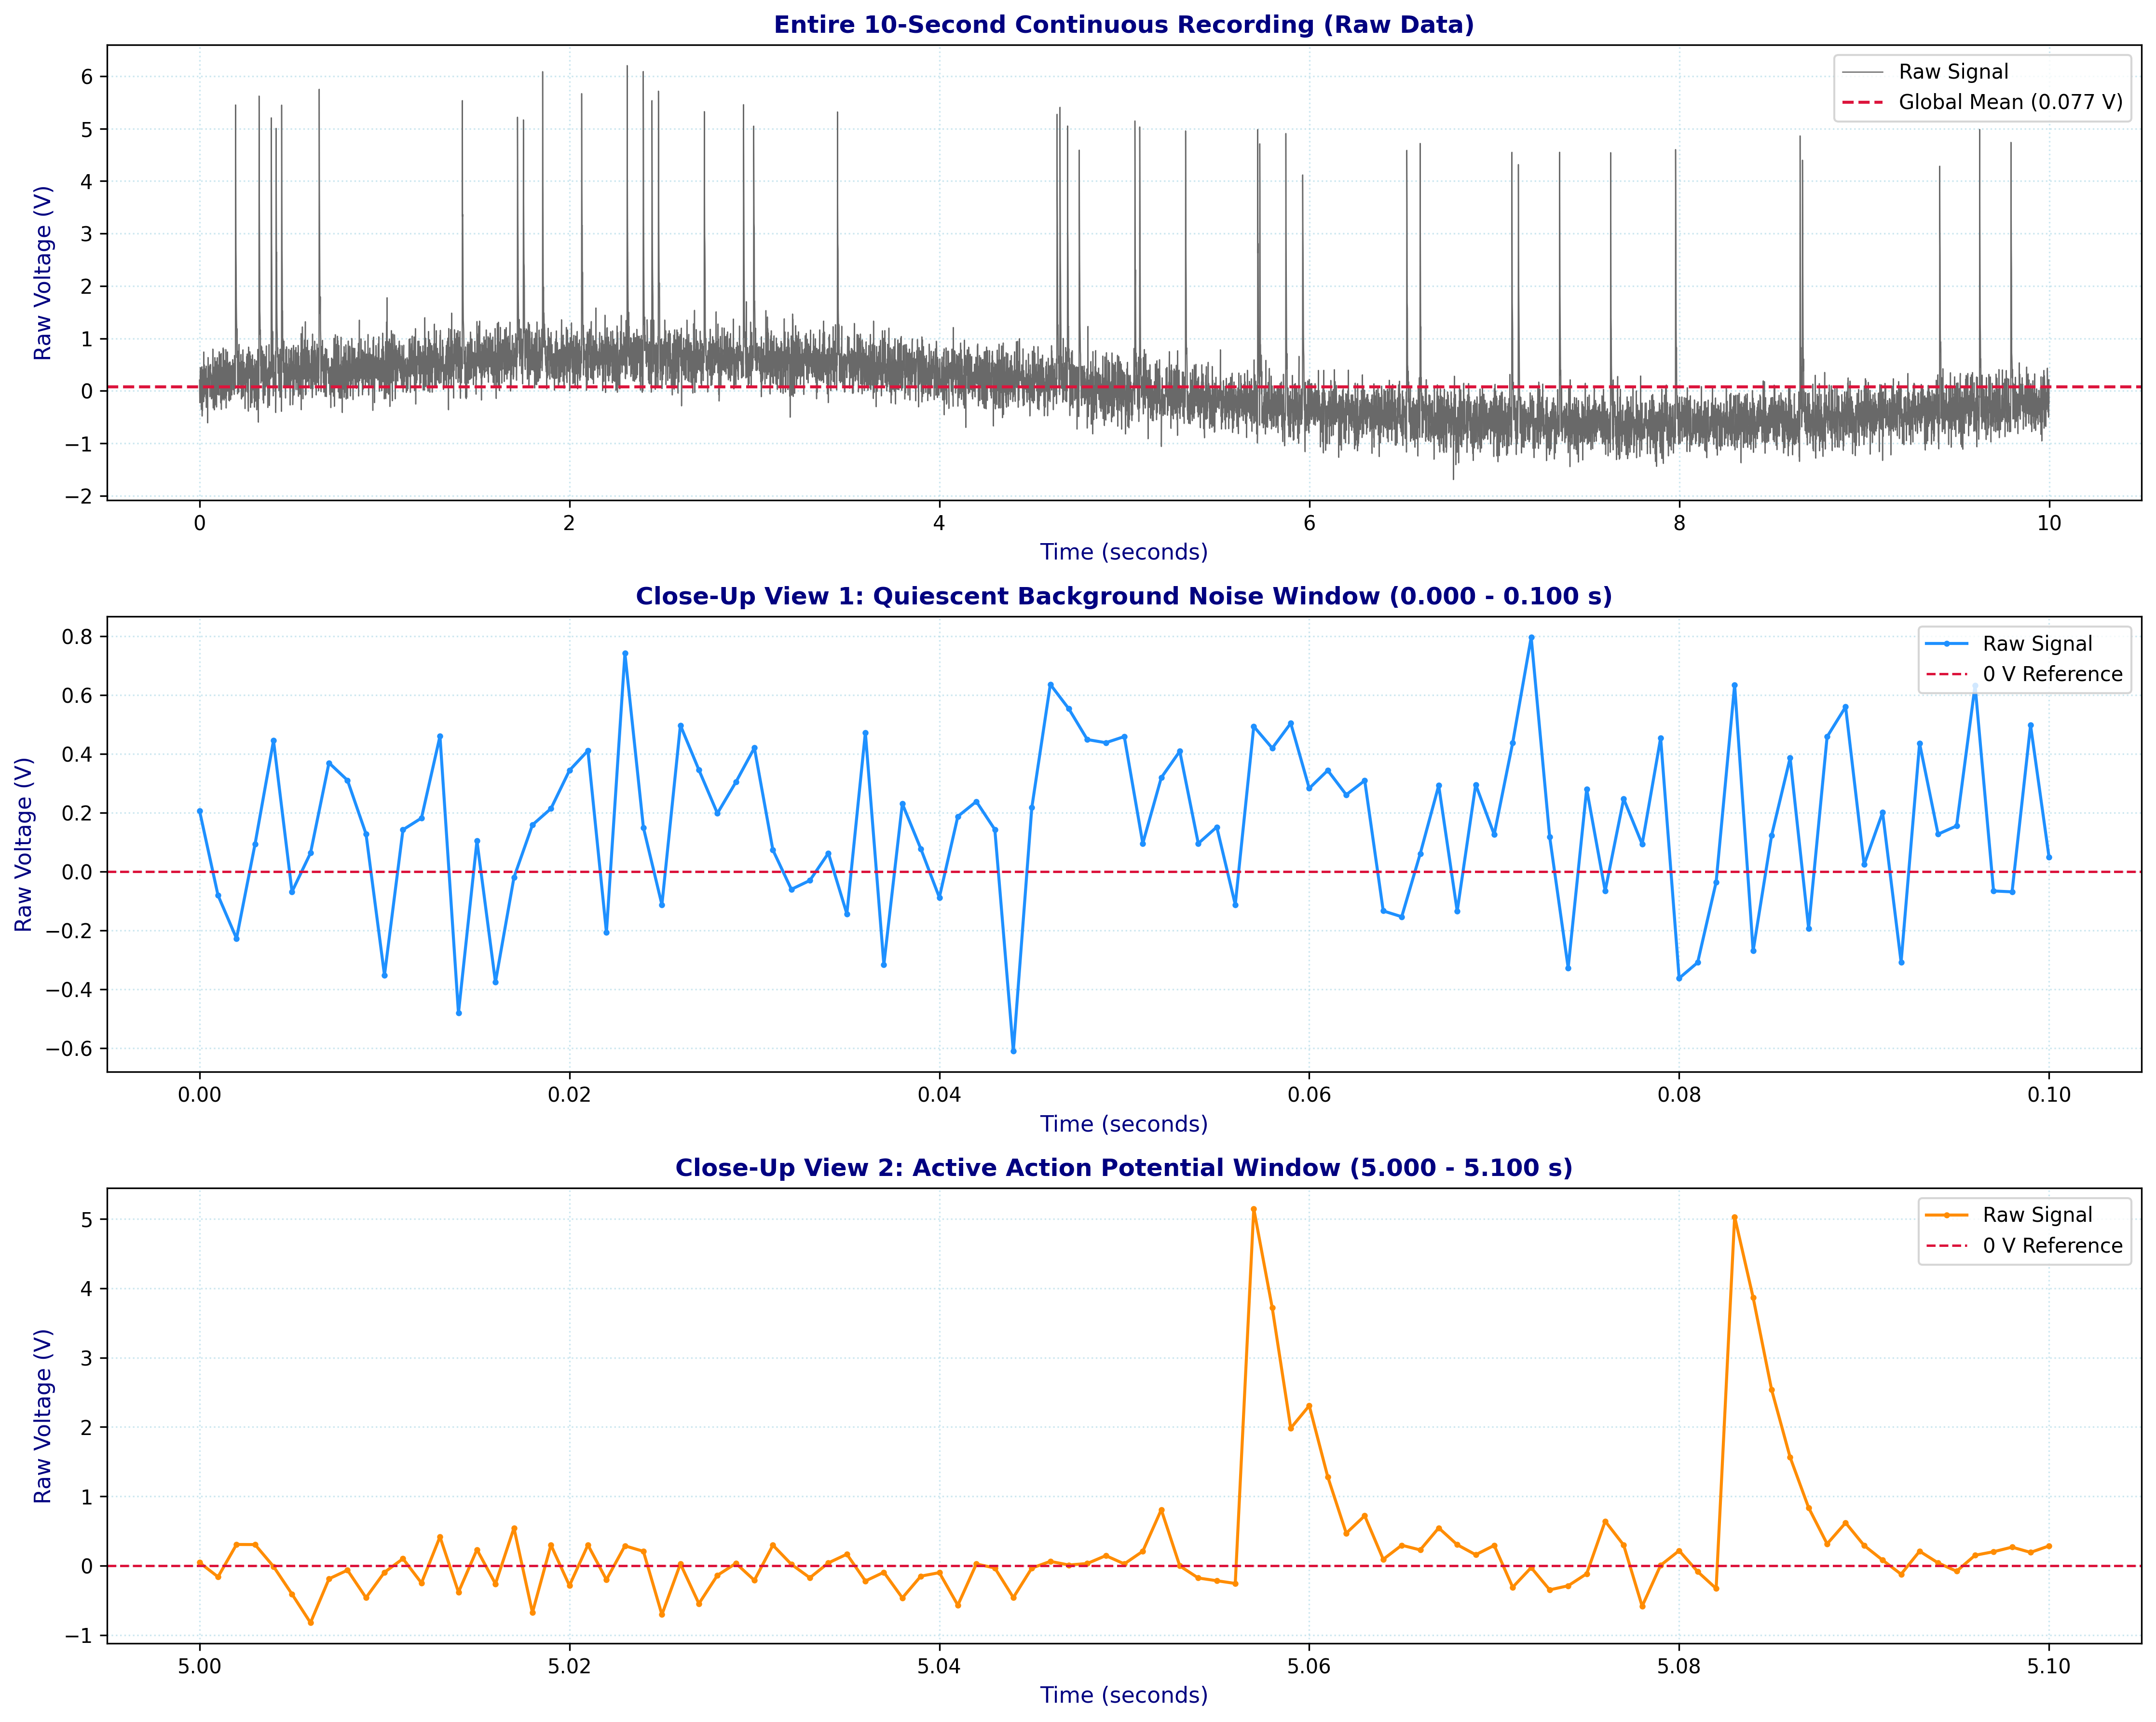

In [32]:
# ==========================================================
# PART 2: Exploratory Data Analysis & Baseline Correction
# ==========================================================

# 1. Baseline Correction via Moving Median Filter (0.15 s window)
window_size = int(0.15 * fs) | 1
baseline = median_filter(raw_data, size=window_size)
signal_centered = raw_data - baseline

# 2. Numerical Summaries (Raw vs Centered)
summary_raw_df = pd.DataFrame({
    'Metric': ['Minimum', 'Maximum', 'Mean', 'Median', 'Standard Deviation (SD)'],
    'Raw Signal': [np.min(raw_data), np.max(raw_data), np.mean(raw_data), np.median(raw_data), np.std(raw_data)],
    'Baseline-Corrected': [np.min(signal_centered), np.max(signal_centered), np.mean(signal_centered), np.median(signal_centered), np.std(signal_centered)]
})

print("=== PART 2: SIGNAL NUMERICAL SUMMARY ===")
display(summary_raw_df)

# 3. Exploratory Visualizations
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Subplot A: Entire 10-Second Recording (Raw Signal)
axes[0].plot(t, raw_data, color='dimgray', linewidth=0.6, label='Raw Signal')
axes[0].axhline(np.mean(raw_data), color='crimson', linestyle='--', linewidth=1.5, label=f'Global Mean ({np.mean(raw_data):.3f} V)')
axes[0].set_title('Entire 10-Second Continuous Recording (Raw Data)', fontsize=12, fontweight='bold', color='navy')
axes[0].set_xlabel('Time (seconds)', fontsize=11, color='navy')
axes[0].set_ylabel('Raw Voltage (V)', fontsize=11, color='navy')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Subplot B: Close-up 1 (Quiescent Initial Window: 0.0 - 0.1 s)
mask_close1 = (t >= 0.0) & (t <= 0.1)
axes[1].plot(t[mask_close1], raw_data[mask_close1], color='dodgerblue', marker='.', markersize=4, label='Raw Signal')
axes[1].axhline(0, color='crimson', linestyle='--', linewidth=1.2, label='0 V Reference')
axes[1].set_title('Close-Up View 1: Quiescent Background Noise Window (0.000 - 0.100 s)', fontsize=12, fontweight='bold', color='navy')
axes[1].set_xlabel('Time (seconds)', fontsize=11, color='navy')
axes[1].set_ylabel('Raw Voltage (V)', fontsize=11, color='navy')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Subplot C: Close-up 2 (Active Spiking Window: 5.0 - 5.1 s)
mask_close2 = (t >= 5.0) & (t <= 5.1)
axes[2].plot(t[mask_close2], raw_data[mask_close2], color='darkorange', marker='.', markersize=4, label='Raw Signal')
axes[2].axhline(0, color='crimson', linestyle='--', linewidth=1.2, label='0 V Reference')
axes[2].set_title('Close-Up View 2: Active Action Potential Window (5.000 - 5.100 s)', fontsize=12, fontweight='bold', color='navy')
axes[2].set_xlabel('Time (seconds)', fontsize=11, color='navy')
axes[2].set_ylabel('Raw Voltage (V)', fontsize=11, color='navy')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle=':', alpha=0.6, color='lightblue')

plt.tight_layout()
plt.show()

In [33]:
# ==========================================================
# PART 3: Custom NumPy Detector & Test Suite
# ==========================================================

def detect_spikes_custom(signal, threshold, min_dist_samples):
    """
    Spike detection engine implemented strictly in pure Python and NumPy.
    Resolves contiguous suprathreshold excursions to their local maximum
    and enforces a minimum refractory distance.
    """
    signal = np.asarray(signal)
    if len(signal) == 0:
        return np.array([], dtype=int)

    above_mask = signal > threshold
    above_indices = np.where(above_mask)[0]

    if len(above_indices) == 0:
        return np.array([], dtype=int)

    # Group adjacent sample indices
    split_points = np.where(np.diff(above_indices) > 1)[0] + 1
    event_groups = np.split(above_indices, split_points)

    # Extract peak for each event group
    raw_peaks = [group[np.argmax(signal[group])] for group in event_groups]

    # Enforce lockout distance
    confirmed_peaks = []
    for p in raw_peaks:
        if not confirmed_peaks or (p - confirmed_peaks[-1]) >= min_dist_samples:
            confirmed_peaks.append(p)
        else:
            if signal[p] > signal[confirmed_peaks[-1]]:
                confirmed_peaks[-1] = p

    return np.array(confirmed_peaks, dtype=int)


def run_unit_tests():
    """Validates the 5 required test cases."""
    th = 1.0
    dist = 3
    tests = [
        {"name": "No samples above threshold", "sig": np.array([0.1, 0.5, -0.2, 0.8, 0.0]), "exp_cnt": 0, "exp_idx": []},
        {"name": "One isolated sample above threshold", "sig": np.array([0.1, 0.2, 1.5, 0.3, 0.0]), "exp_cnt": 1, "exp_idx": [2]},
        {"name": "Several consecutive samples above threshold", "sig": np.array([0.2, 1.2, 1.8, 1.4, 0.1]), "exp_cnt": 1, "exp_idx": [2]},
        {"name": "Two separate above-threshold intervals", "sig": np.array([0.0, 1.5, 0.1, 0.0, 0.0, 1.6, 0.2]), "exp_cnt": 2, "exp_idx": [1, 5]},
        {"name": "Signal starts above threshold", "sig": np.array([1.5, 1.2, 0.1, 0.0, 1.7, 0.2]), "exp_cnt": 2, "exp_idx": [0, 4]}
    ]

    print("=== PART 3: RUNNING UNIT TESTS ===")
    all_ok = True
    for idx, test in enumerate(tests, 1):
        res = detect_spikes_custom(test["sig"], threshold=th, min_dist_samples=dist)
        is_cnt_ok = len(res) == test["exp_cnt"]
        is_idx_ok = np.array_equal(res, test["exp_idx"])
        status = "PASSED" if (is_cnt_ok and is_idx_ok) else "FAILED"
        if status == "FAILED":
            all_ok = False
        print(f"Test {idx}: {test['name']:<48} -> [{status}]")

    print("-" * 65)
    print("STATUS: ALL 5 UNIT TESTS PASSED SUCCESSFULLY!\n" if all_ok else "STATUS: TESTS FAILED.\n")

run_unit_tests()

=== PART 3: RUNNING UNIT TESTS ===
Test 1: No samples above threshold                       -> [PASSED]
Test 2: One isolated sample above threshold              -> [PASSED]
Test 3: Several consecutive samples above threshold      -> [PASSED]
Test 4: Two separate above-threshold intervals           -> [PASSED]
Test 5: Signal starts above threshold                    -> [PASSED]
-----------------------------------------------------------------
STATUS: ALL 5 UNIT TESTS PASSED SUCCESSFULLY!



In [34]:
# ==========================================================
# PART 3: Empirical Valley Selection & Dual-Refractory Execution
# ==========================================================

# 1. Noise Floor Estimation via Median Absolute Deviation (MAD)
med = np.median(signal_centered)
mad = np.median(np.abs(signal_centered - med))
sigma_n = mad / 0.6745

# 2. Extract Candidate Local Maxima
is_local_max = (
    (signal_centered[1:-1] > signal_centered[:-2]) &
    (signal_centered[1:-1] > signal_centered[2:]) &
    (signal_centered[1:-1] > 0)
)
local_max_indices = np.where(is_local_max)[0] + 1
local_max_voltages = signal_centered[local_max_indices]

# 3. Dynamic Empirical Valley Search
hist_counts, bin_edges = np.histogram(local_max_voltages, bins=40)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

noise_ceiling = med + (3.0 * sigma_n)
spike_upper_bound = np.percentile(local_max_voltages, 99.0)
search_mask = (bin_centers >= noise_ceiling) & (bin_centers <= spike_upper_bound)

if np.any(search_mask) and np.sum(search_mask) >= 2:
    valley_idx = np.argmin(hist_counts[search_mask])
    empirical_threshold = bin_centers[search_mask][valley_idx]
else:
    empirical_threshold = med + (4.0 * sigma_n)

# Lockout samples calculation (4 ms separation for strictly > 3 ms lockout)
min_distance_samples = max(1, int(0.003 * fs) + 1)

# 4. Method 1 Detection (Absolute Peak-to-Peak Lockout)
m1_indices = detect_spikes_custom(signal_centered, empirical_threshold, min_dist_samples=min_distance_samples)
m1_times = t[m1_indices]
m1_voltages = signal_centered[m1_indices]

# 5. Method 2 Detection (Post-Threshold-Drop Relative Lockout)
def detect_spikes_post_drop(signal, threshold, lockout_ms, fs_rate):
    lockout_samples = int((lockout_ms / 1000.0) * fs_rate)
    above_mask = signal > threshold
    raw_peak_indices = np.where(
        (signal[1:-1] > signal[:-2]) &
        (signal[1:-1] > signal[2:]) &
        above_mask[1:-1]
    )[0] + 1

    validated_peaks = []
    lockout_intervals = []
    i = 0
    while i < len(raw_peak_indices):
        current_peak_idx = raw_peak_indices[i]
        validated_peaks.append(current_peak_idx)

        # Advance until signal drops strictly below threshold
        drop_idx = current_peak_idx
        while drop_idx < len(signal) and signal[drop_idx] >= threshold:
            drop_idx += 1

        lockout_start = drop_idx
        lockout_end = min(len(signal) - 1, lockout_start + lockout_samples)
        lockout_intervals.append((t[lockout_start], t[lockout_end]))

        next_i = i + 1
        while next_i < len(raw_peak_indices) and raw_peak_indices[next_i] <= lockout_end:
            next_i += 1
        i = next_i

    return np.array(validated_peaks, dtype=int), lockout_intervals

m2_indices, m2_lockout_intervals = detect_spikes_post_drop(
    signal_centered, empirical_threshold, lockout_ms=3.0, fs_rate=fs
)
m2_times = t[m2_indices]
m2_voltages = signal_centered[m2_indices]

# Print Comparative Metrics
print("=== THRESHOLD & REFRACTORY COMPARISON RESULTS ===")
print(f"Estimated Noise Floor (sigma_n):          {sigma_n:.4f} V")
print(f"Calculated Empirical Valley Threshold:    {empirical_threshold:.4f} V")
print(f"Method 1 (Absolute Peak-to-Peak Lockout): {len(m1_times)} spikes | Firing Rate: {len(m1_times)/duration:.2f} Hz")
print(f"Method 2 (Post-Threshold-Drop Lockout):    {len(m2_times)} spikes | Firing Rate: {len(m2_times)/duration:.2f} Hz")
print(f"Spike Count Discrepancy:                  {len(m1_times) - len(m2_times)} spikes")

# Verify Refractory Violations
isi_m1 = np.diff(m1_times) * 1000.0
isi_m2 = np.diff(m2_times) * 1000.0
print(f"Method 1 Violations (< 3.0 ms):           {np.sum(isi_m1 < 3.0)}")
print(f"Method 2 Violations (< 3.0 ms):           {np.sum(isi_m2 < 3.0)}\n")

# Display First 15 Detected Spikes
spike_audit_df = pd.DataFrame({
    'Spike Index': np.arange(1, len(m1_times) + 1),
    'Peak Sample': m1_indices,
    'Time (s)': m1_times,
    'Peak Voltage (V)': m1_voltages
})
print("=== FIRST 15 DETECTED SPIKES (METHOD 1 AUDIT) ===")
display(spike_audit_df.head(15))

=== THRESHOLD & REFRACTORY COMPARISON RESULTS ===
Estimated Noise Floor (sigma_n):          0.3111 V
Calculated Empirical Valley Threshold:    1.8673 V
Method 1 (Absolute Peak-to-Peak Lockout): 42 spikes | Firing Rate: 4.20 Hz
Method 2 (Post-Threshold-Drop Lockout):    42 spikes | Firing Rate: 4.20 Hz
Spike Count Discrepancy:                  0 spikes
Method 1 Violations (< 3.0 ms):           0
Method 2 Violations (< 3.0 ms):           0

=== FIRST 15 DETECTED SPIKES (METHOD 1 AUDIT) ===


,Spike Index,Peak Sample,Time (s),Peak Voltage (V)
0,1,195,0.195,5.110396
1,2,322,0.322,5.252447
2,3,388,0.388,4.776310
3,4,414,0.414,4.619756
4,5,444,0.444,5.049348
5,6,647,0.647,5.309754
6,7,1421,1.421,4.899313
7,8,1719,1.719,4.516386
8,9,1751,1.751,4.470131
9,10,1855,1.855,5.431939


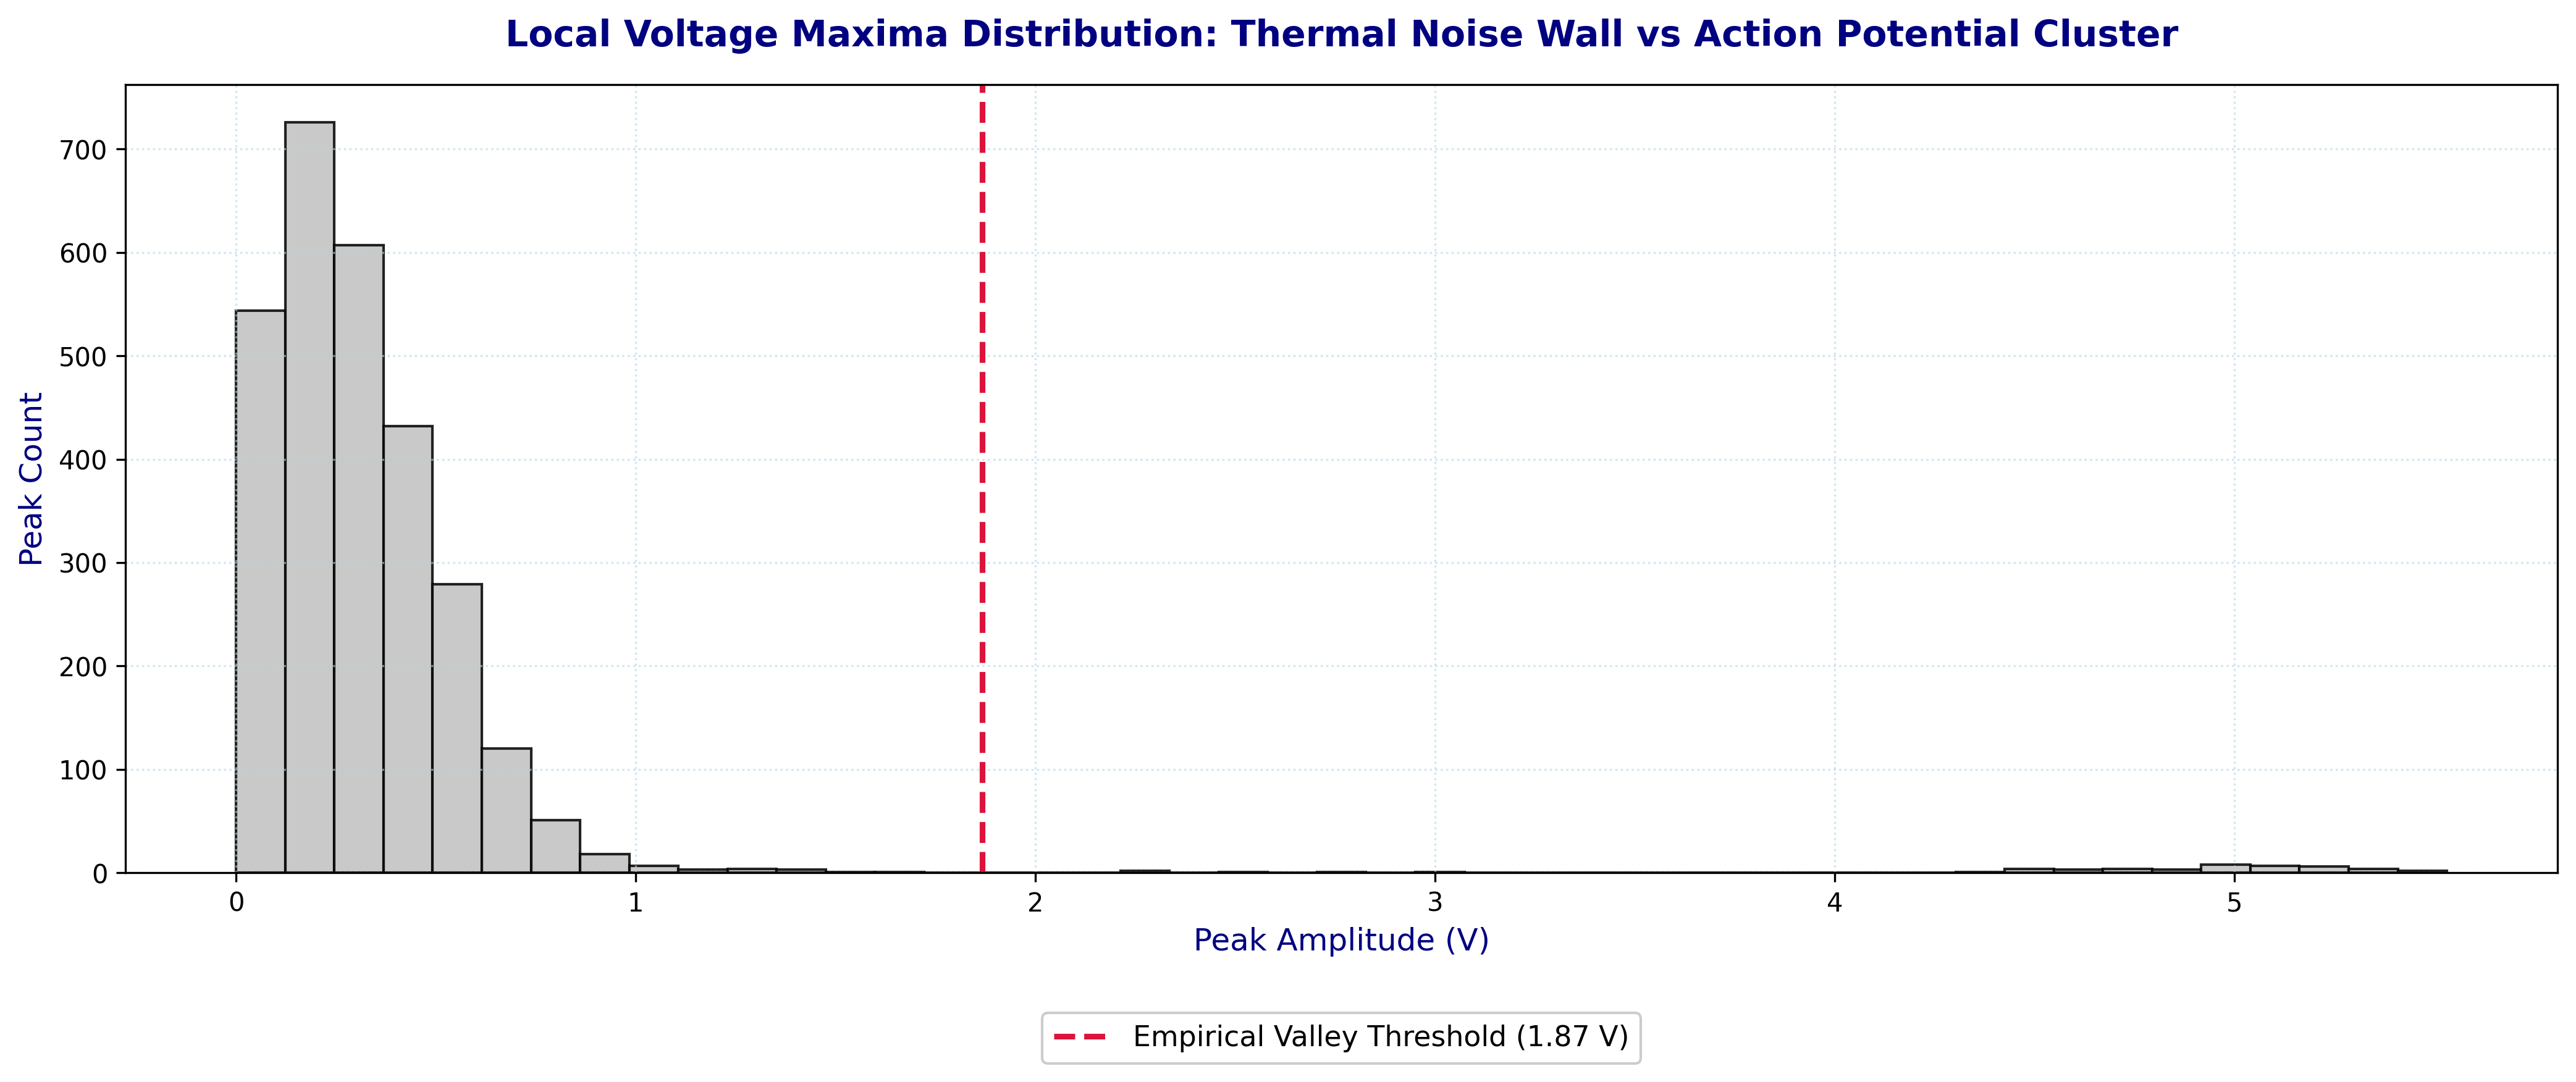

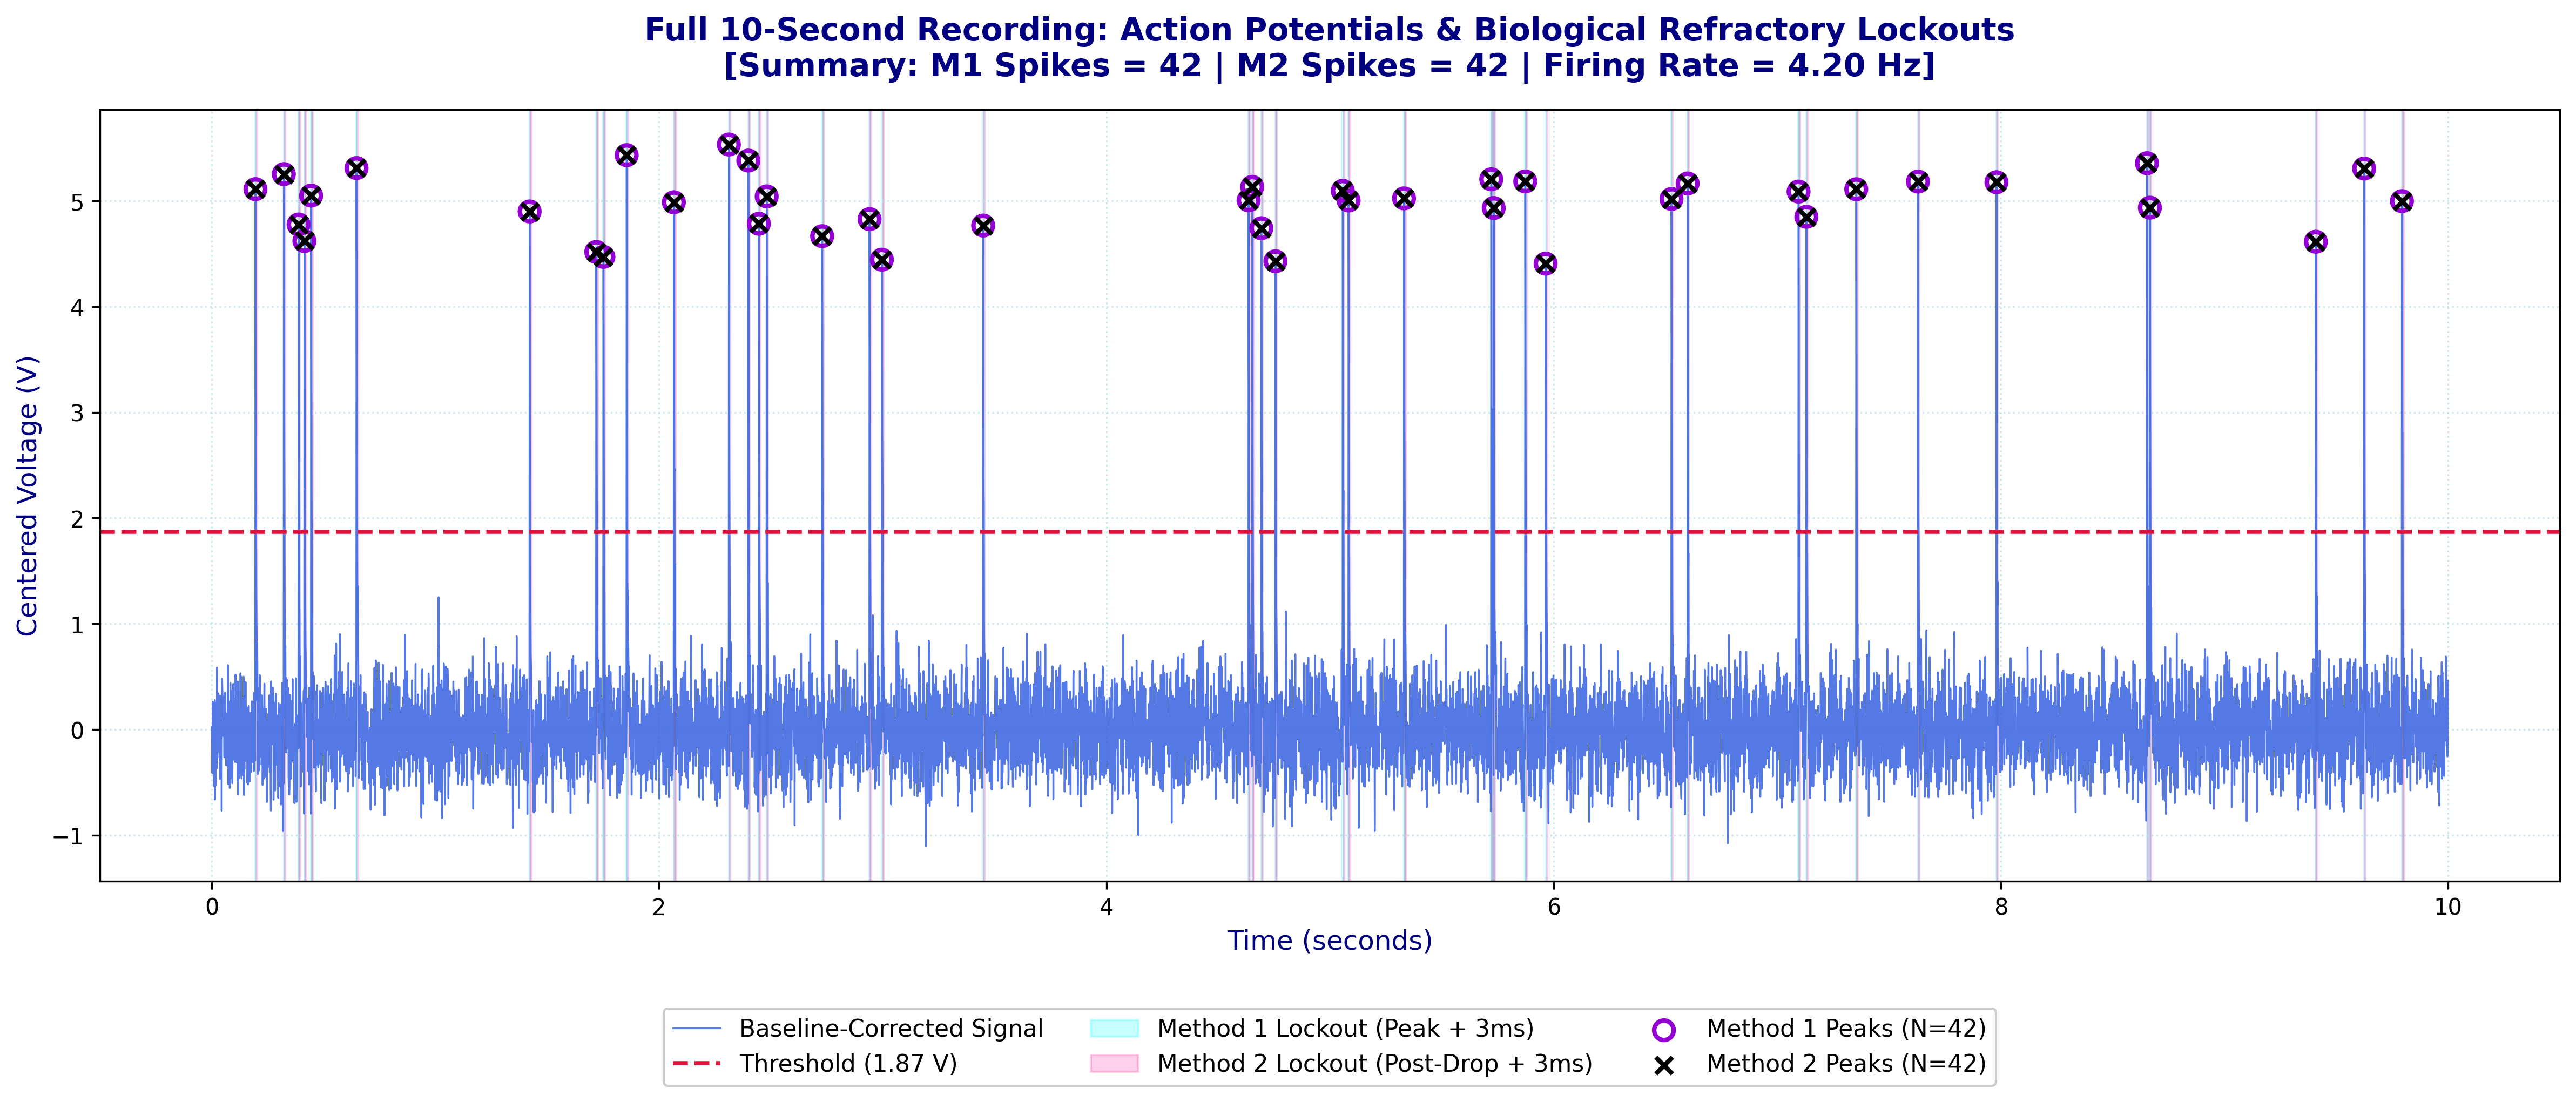

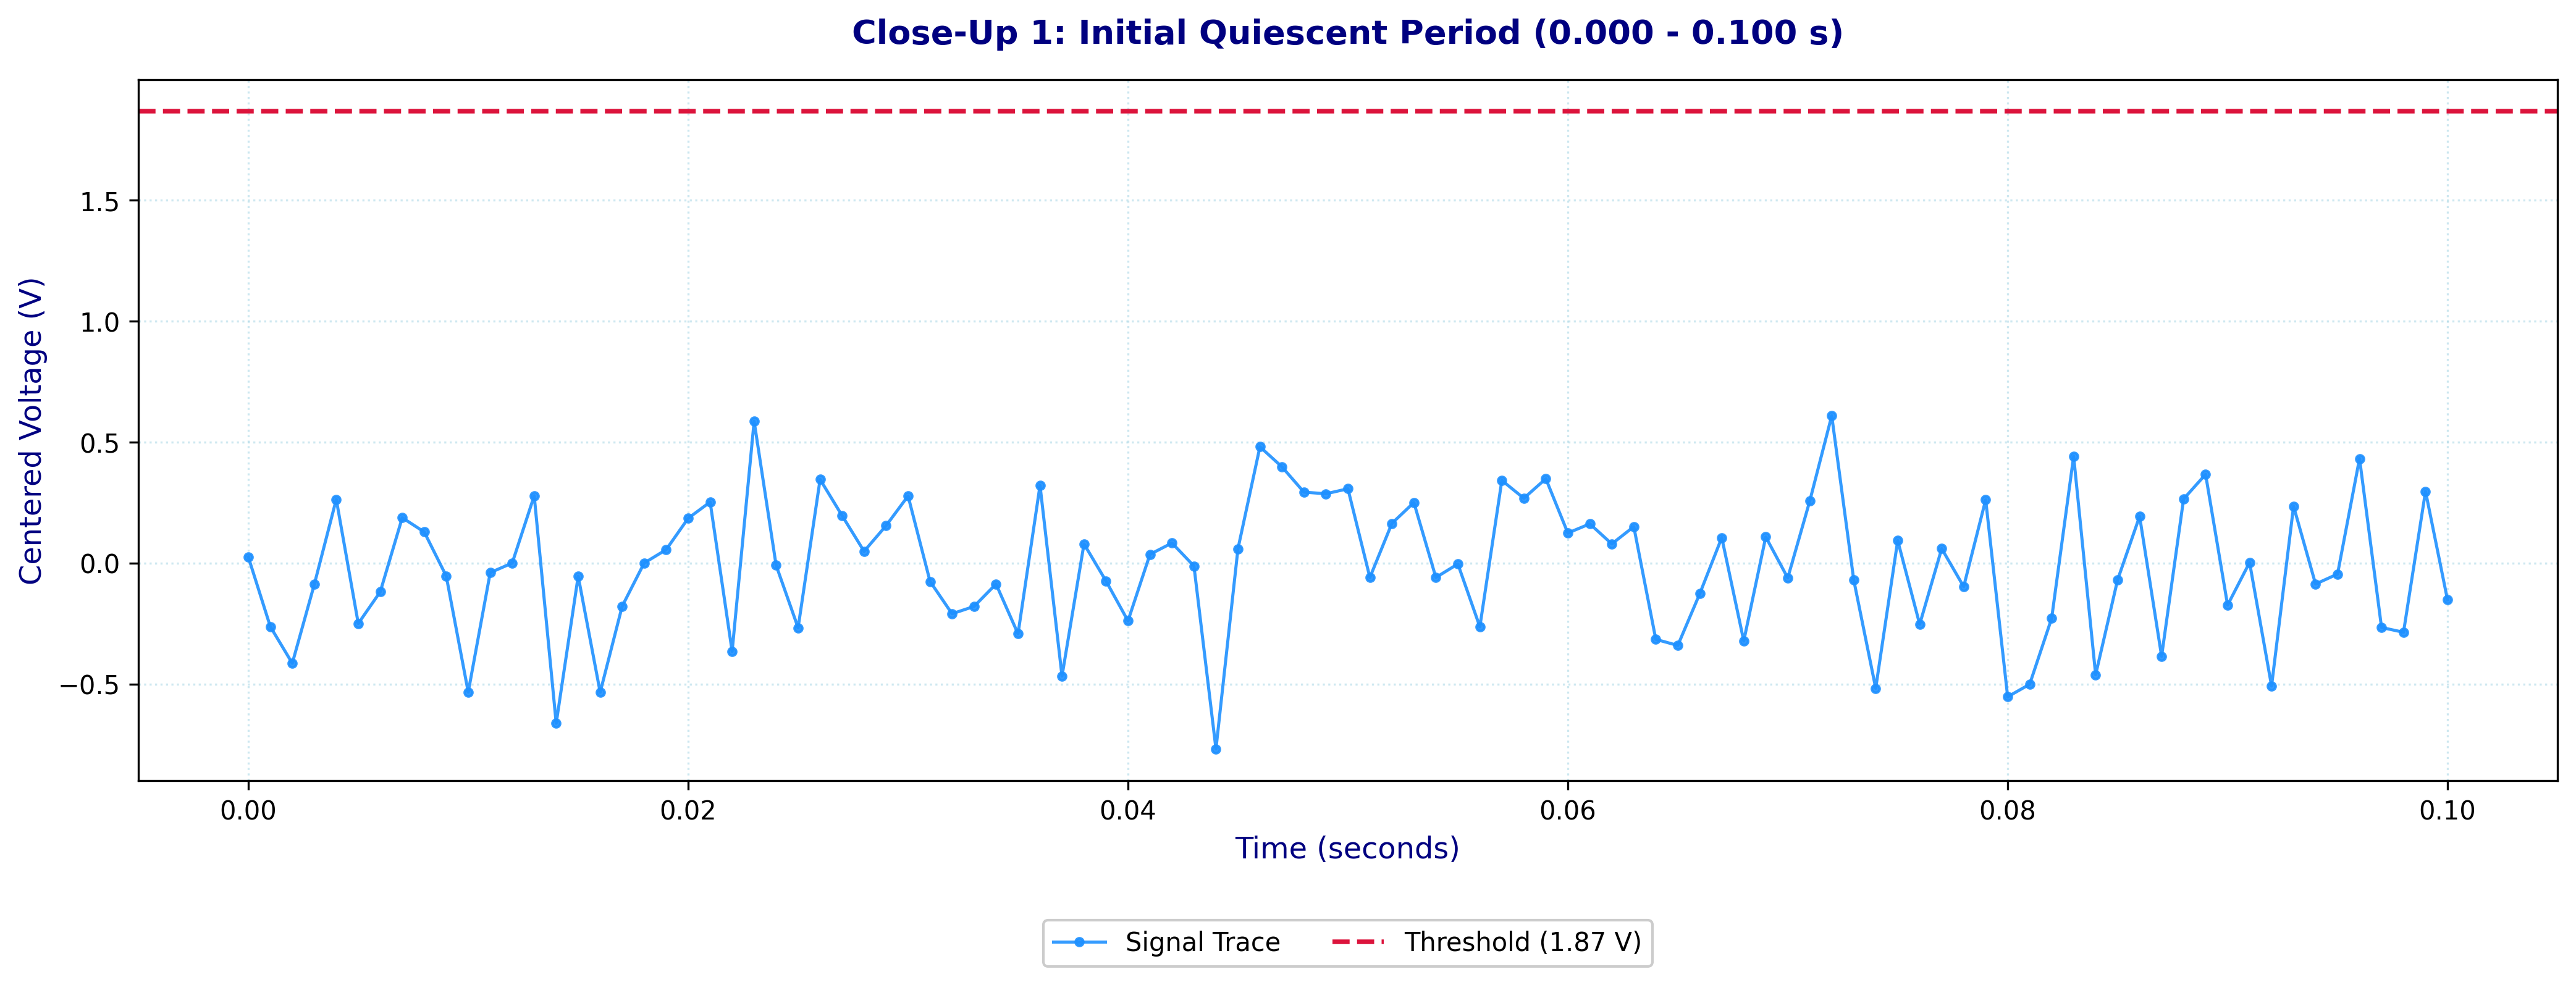

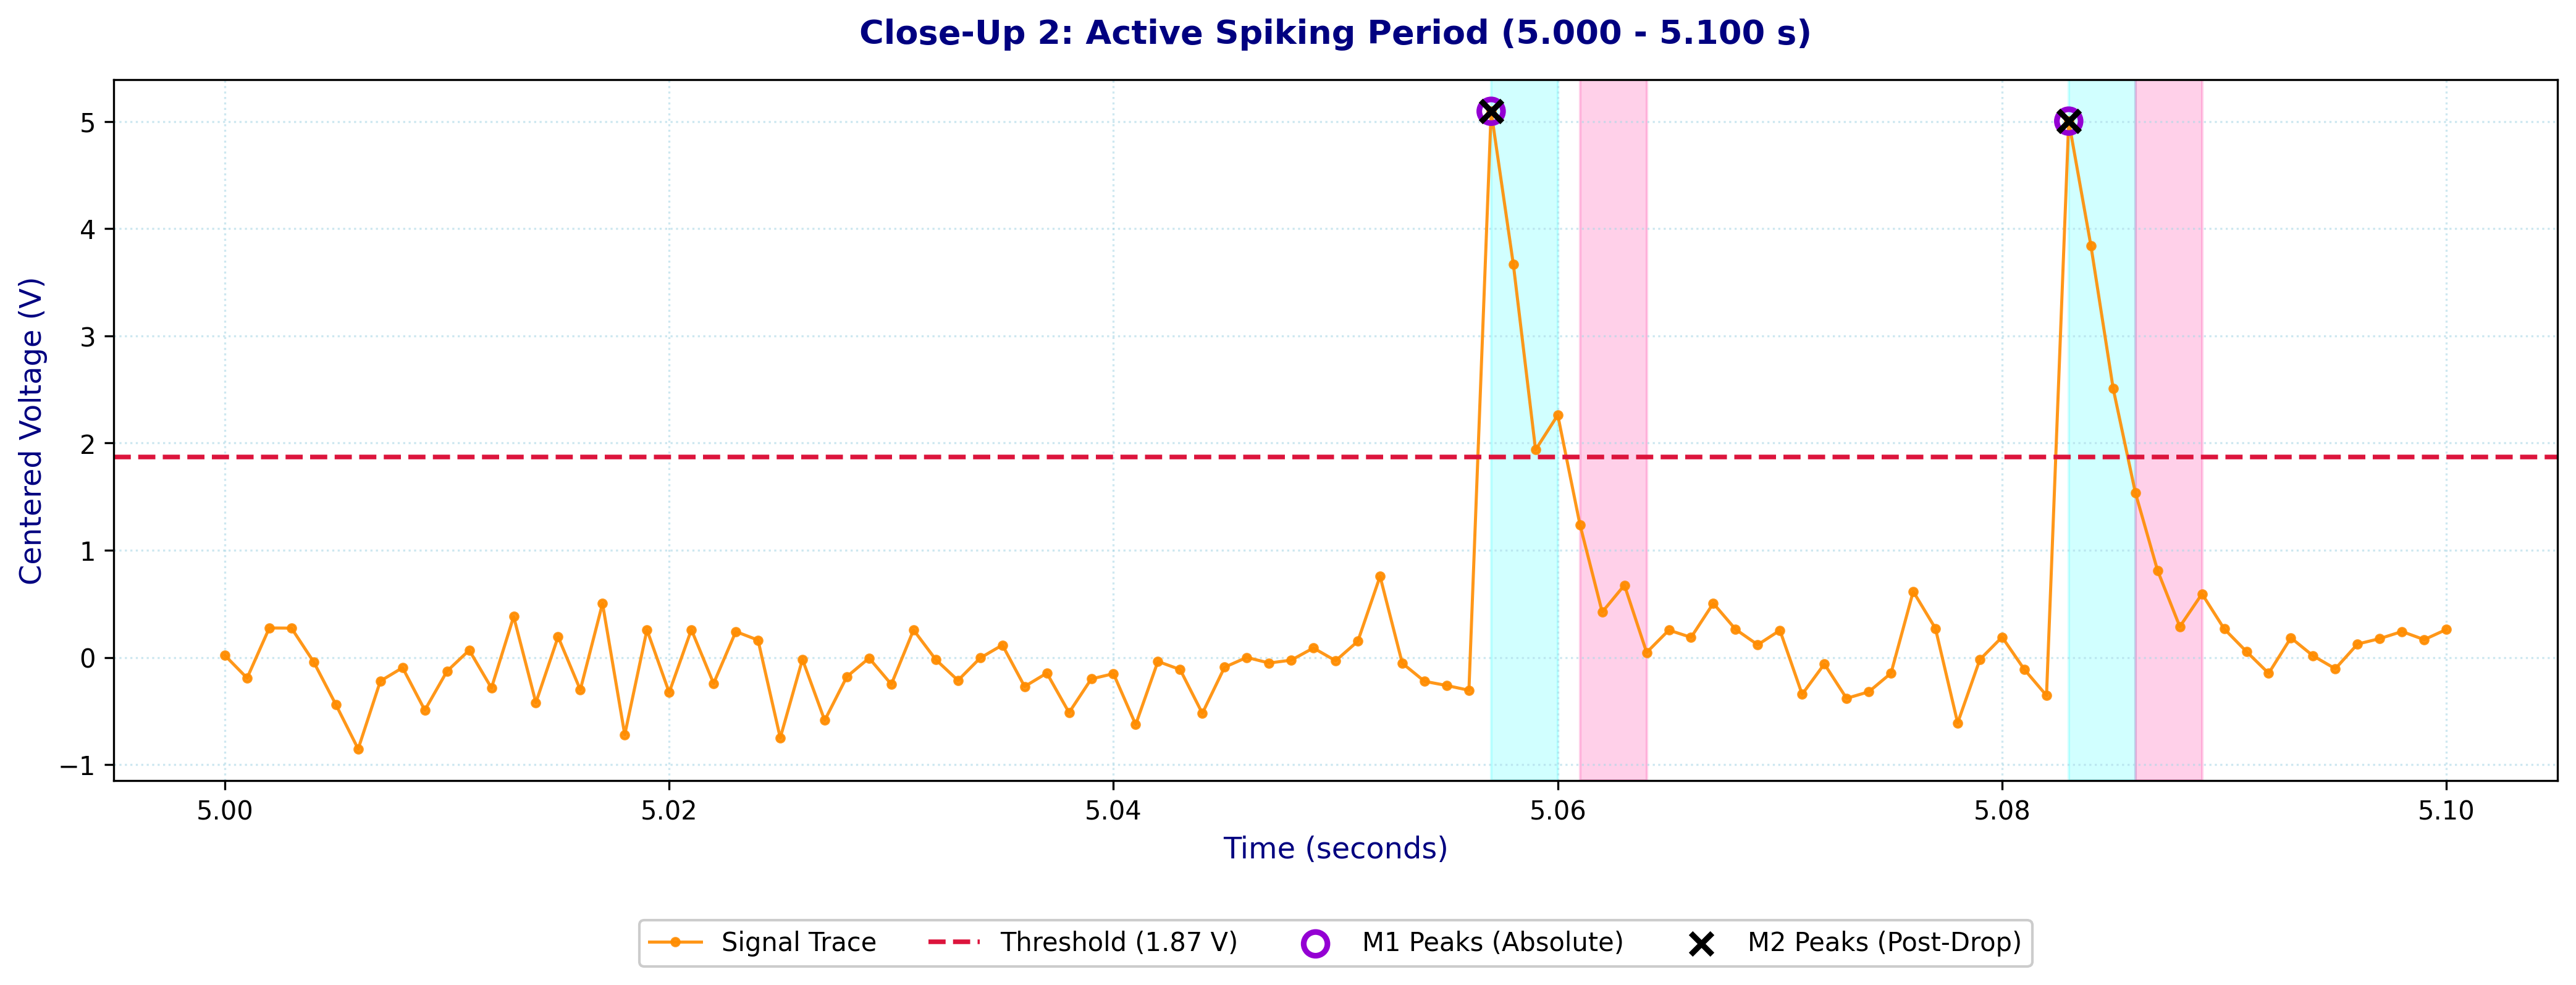

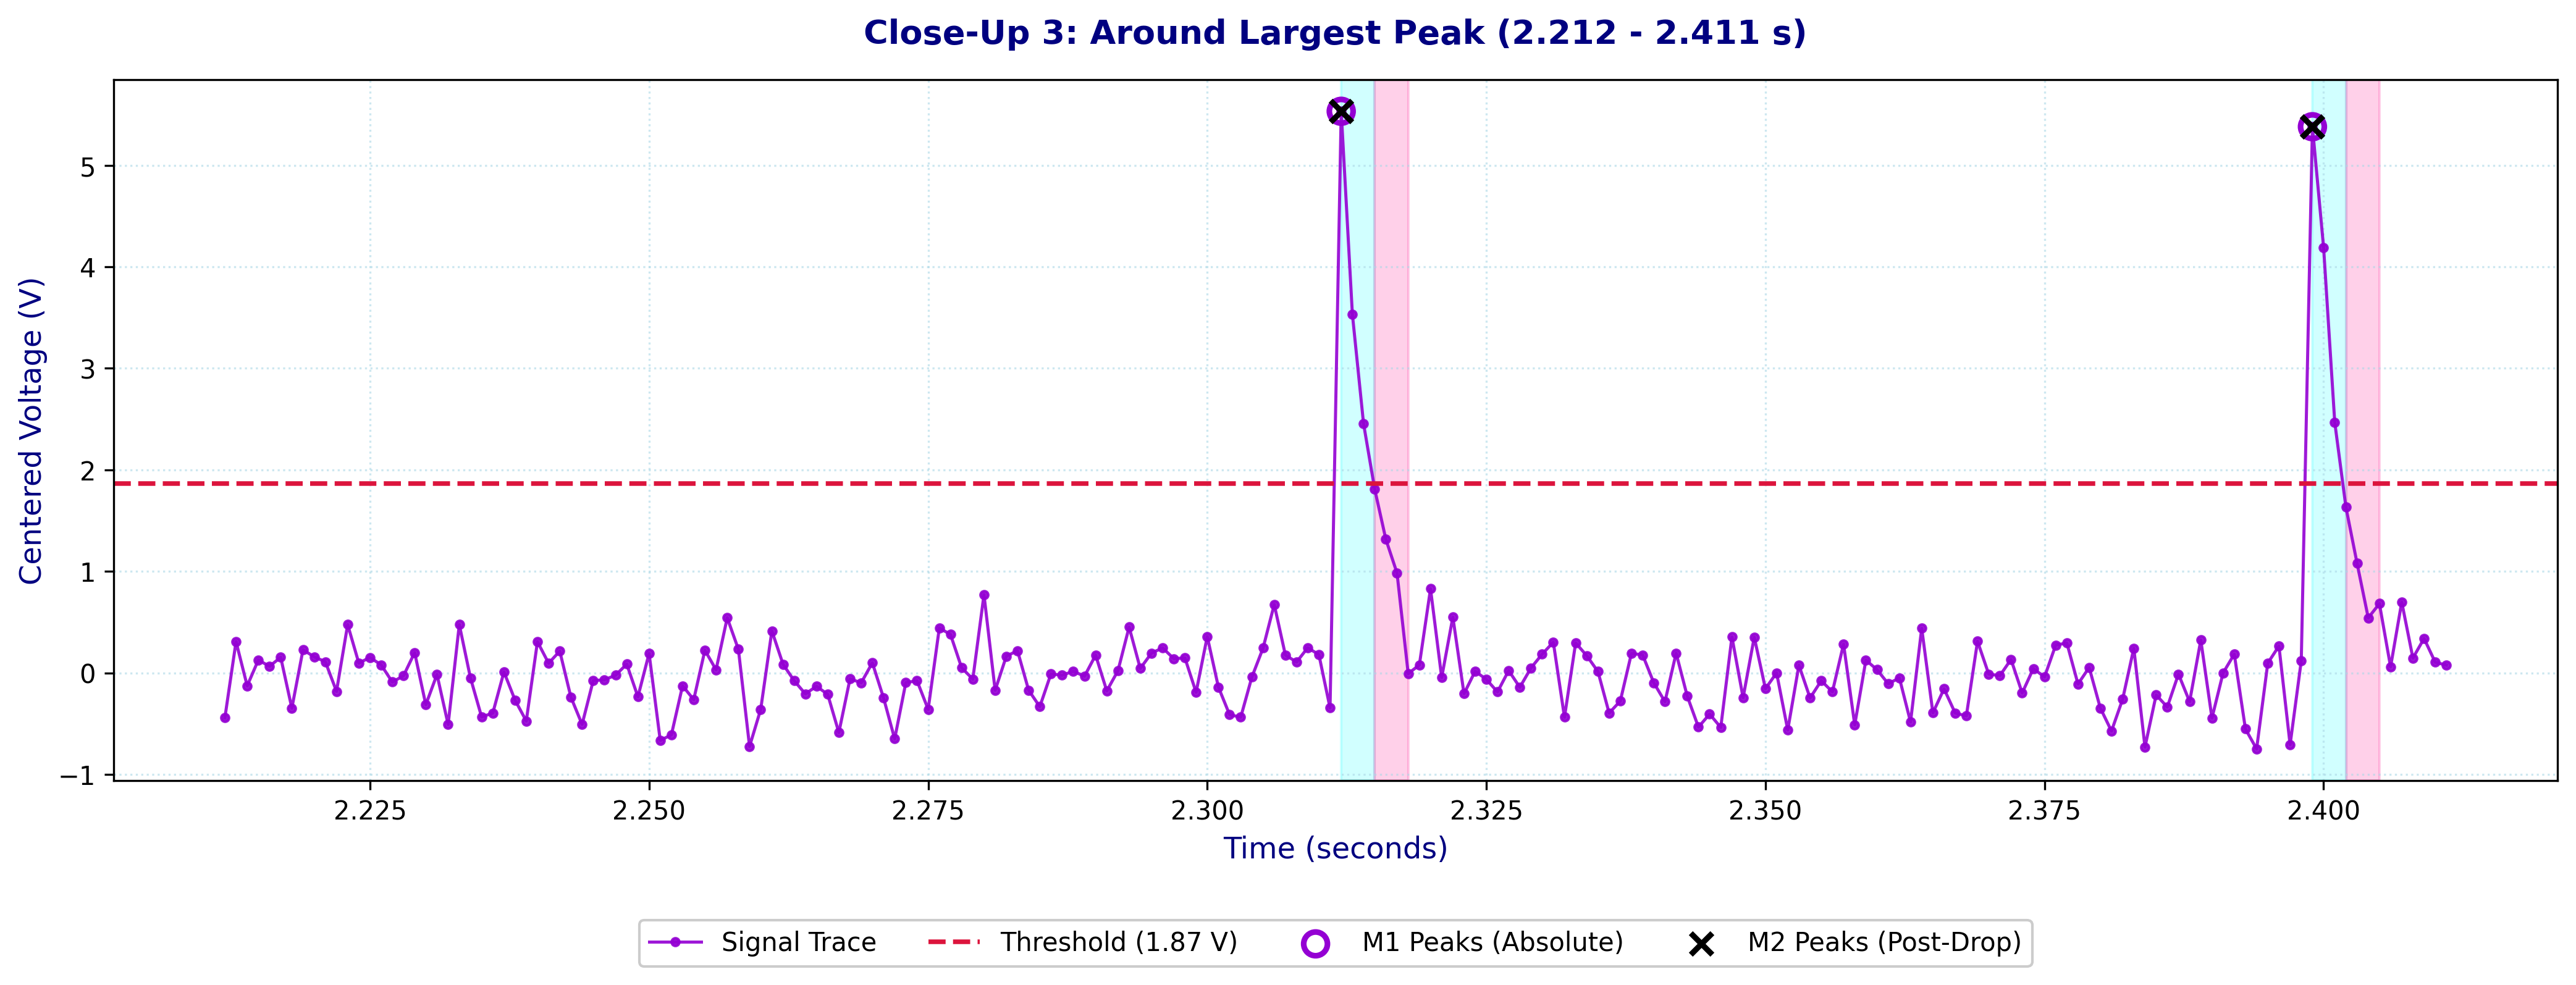

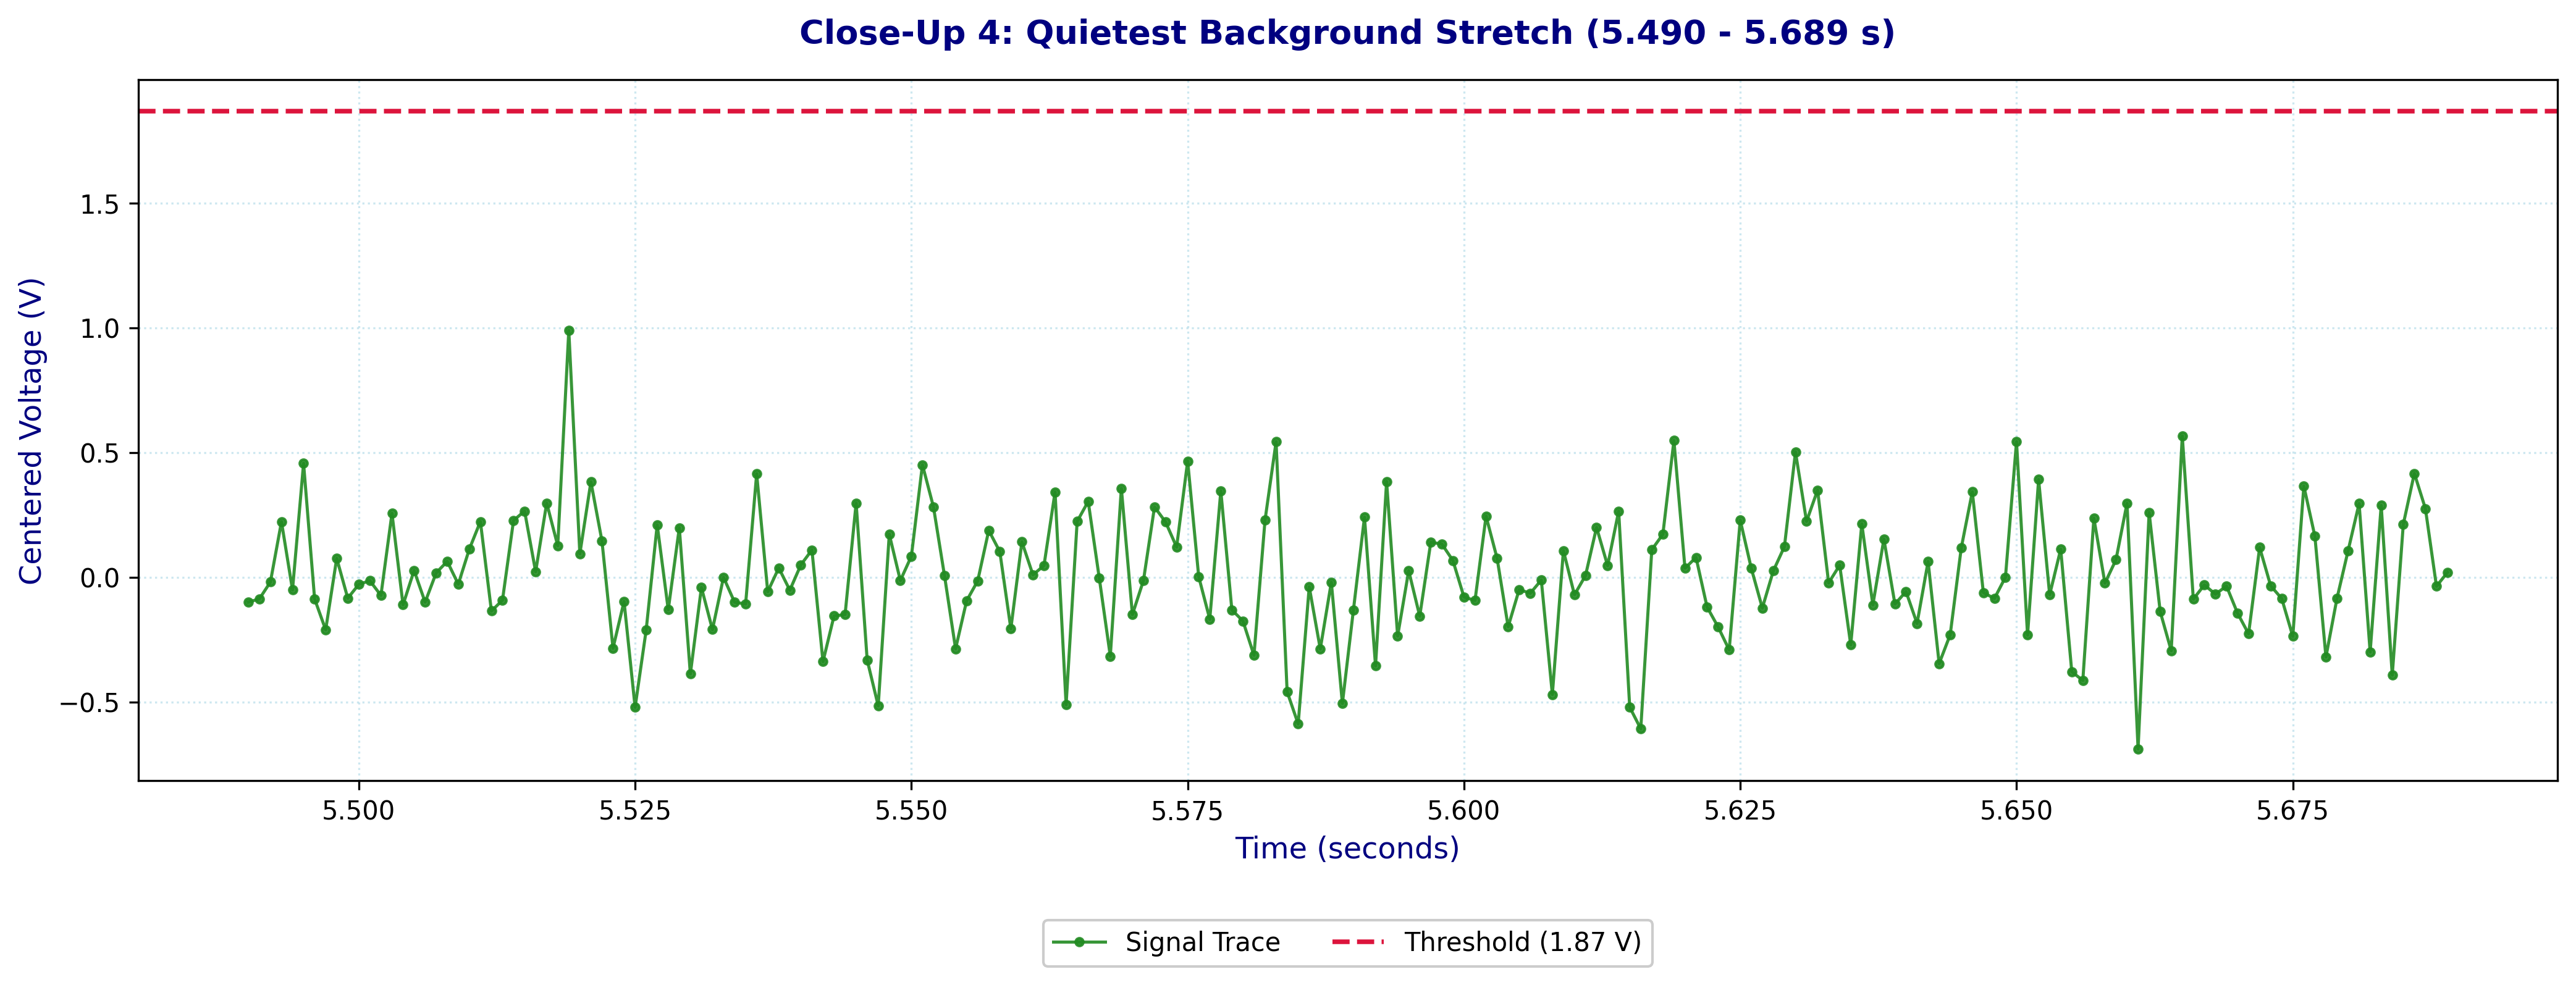

In [35]:
# ==========================================================
# PART 3: High-Resolution Individual Visualizations
# ==========================================================

# Set global high-DPI rendering so every figure displays crisp and sharp in Colab
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300


# ----------------------------------------------------------
# Plot 1: Peak Amplitude Distribution (Empirical Valley)
# ----------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(14, 6))

ax1.hist(
    local_max_voltages,
    bins=45,
    color='silver',
    edgecolor='black',
    alpha=0.85
)
ax1.axvline(
    empirical_threshold,
    color='crimson',
    linestyle='--',
    linewidth=2.2,
    label=f'Empirical Valley Threshold ({empirical_threshold:.2f} V)'
)

ax1.set_title(
    "Local Voltage Maxima Distribution: Thermal Noise Wall vs Action Potential Cluster",
    fontsize=14,
    fontweight='bold',
    color='navy',
    pad=15
)
ax1.set_xlabel("Peak Amplitude (V)", fontsize=12, color='navy')
ax1.set_ylabel("Peak Count", fontsize=12, color='navy')
ax1.grid(True, linestyle=':', alpha=0.6, color='lightblue')
ax1.tick_params(axis='both', which='major', labelsize=10)

ax1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
    frameon=True,
    facecolor='white',
    edgecolor='silver',
    fontsize=11
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Plot 2: Full 10-Second Recording with Detected Peaks & Lockouts
# ----------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(16, 7))

ax2.plot(
    t,
    signal_centered,
    color='royalblue',
    linewidth=0.8,
    alpha=0.9,
    label='Baseline-Corrected Signal'
)
ax2.axhline(
    empirical_threshold,
    color='crimson',
    linestyle='--',
    linewidth=1.8,
    label=f'Threshold ({empirical_threshold:.2f} V)'
)

# Shade Method 1 Lockouts (3ms from peak)[cite: 20]
first_m1 = True
for pt in m1_times:
    ax2.axvspan(
        pt, pt + 0.003,
        color='cyan',
        alpha=0.22,
        label='Method 1 Lockout (Peak + 3ms)' if first_m1 else ""
    )
    first_m1 = False

# Shade Method 2 Lockouts (post-threshold-drop)[cite: 18, 20]
first_m2 = True
for start_t, end_t in m2_lockout_intervals:
    ax2.axvspan(
        start_t, end_t,
        color='deeppink',
        alpha=0.20,
        label='Method 2 Lockout (Post-Drop + 3ms)' if first_m2 else ""
    )
    first_m2 = False

ax2.scatter(
    m1_times, m1_voltages,
    color='darkviolet',
    s=75,
    marker='o',
    facecolors='none',
    edgecolors='darkviolet',
    linewidths=2.0,
    zorder=5,
    label=f'Method 1 Peaks (N={len(m1_times)})'
)
ax2.scatter(
    m2_times, m2_voltages,
    color='black',
    s=55,
    marker='x',
    linewidths=2.0,
    zorder=6,
    label=f'Method 2 Peaks (N={len(m2_times)})'
)

ax2.set_title(
    f"Full 10-Second Recording: Action Potentials & Biological Refractory Lockouts\n"
    f"[Summary: M1 Spikes = {len(m1_times)} | M2 Spikes = {len(m2_times)} | Firing Rate = {len(m1_times)/duration:.2f} Hz]",
    fontsize=14,
    fontweight='bold',
    color='navy',
    pad=15
)
ax2.set_xlabel("Time (seconds)", fontsize=12, color='navy')
ax2.set_ylabel("Centered Voltage (V)", fontsize=12, color='navy')
ax2.grid(True, linestyle=':', alpha=0.6, color='lightblue')
ax2.tick_params(axis='both', which='major', labelsize=10)

ax2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=True,
    facecolor='white',
    edgecolor='silver',
    fontsize=10.5
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Setup for Individual Close-Up Plots[cite: 11, 20]
# ----------------------------------------------------------
win_samples = int(0.2 * fs)
i_peak = np.argmax(np.abs(signal_centered))
a0 = max(0, i_peak - win_samples // 2)

local_std = pd.Series(signal_centered).rolling(win_samples).std().to_numpy()
b_end = np.nanargmin(local_std)
b0 = max(0, b_end - win_samples + 1)

close_up_configs = [
    {
        'mask': (t >= 0.0) & (t <= 0.1),
        'title': 'Close-Up 1: Initial Quiescent Period (0.000 - 0.100 s)',
        'color': 'dodgerblue'
    },
    {
        'mask': (t >= 5.0) & (t <= 5.1),
        'title': 'Close-Up 2: Active Spiking Period (5.000 - 5.100 s)',
        'color': 'darkorange'
    },
    {
        'slice': slice(a0, a0 + win_samples),
        'title': f'Close-Up 3: Around Largest Peak ({t[a0]:.3f} - {t[a0 + win_samples - 1]:.3f} s)',
        'color': 'darkviolet'
    },
    {
        'slice': slice(b0, b0 + win_samples),
        'title': f'Close-Up 4: Quietest Background Stretch ({t[b0]:.3f} - {t[b0 + win_samples - 1]:.3f} s)',
        'color': 'forestgreen'
    }
]


# ----------------------------------------------------------
# Plots 3 to 6: High-Clarity Individual Close-Up Audits
# ----------------------------------------------------------
for cfg in close_up_configs:
    fig, ax = plt.subplots(figsize=(14, 5.5))

    if 'mask' in cfg:
        t_seg = t[cfg['mask']]
        sig_seg = signal_centered[cfg['mask']]
    else:
        t_seg = t[cfg['slice']]
        sig_seg = signal_centered[cfg['slice']]

    ax.plot(
        t_seg,
        sig_seg,
        color=cfg['color'],
        marker='.',
        markersize=6,
        linewidth=1.2,
        alpha=0.9,
        label='Signal Trace'
    )
    ax.axhline(
        empirical_threshold,
        color='crimson',
        linestyle='--',
        linewidth=1.8,
        label=f'Threshold ({empirical_threshold:.2f} V)'
    )

    # Method 1 peaks in this segment
    m1_in_seg = m1_times[(m1_times >= t_seg[0]) & (m1_times <= t_seg[-1])]
    if len(m1_in_seg) > 0:
        m1_v = signal_centered[np.searchsorted(t, m1_in_seg)]
        ax.scatter(
            m1_in_seg,
            m1_v,
            color='darkviolet',
            s=85,
            marker='o',
            facecolors='none',
            edgecolors='darkviolet',
            linewidths=2.2,
            zorder=5,
            label='M1 Peaks (Absolute)'
        )
        for pt in m1_in_seg:
            ax.axvspan(pt, pt + 0.003, color='cyan', alpha=0.18)

    # Method 2 peaks in this segment (solid black 'x' markers)
    m2_in_seg = m2_times[(m2_times >= t_seg[0]) & (m2_times <= t_seg[-1])]
    if len(m2_in_seg) > 0:
        m2_v = signal_centered[np.searchsorted(t, m2_in_seg)]
        ax.scatter(
            m2_in_seg,
            m2_v,
            color='black',
            s=70,
            marker='x',
            linewidths=2.2,
            zorder=6,
            label='M2 Peaks (Post-Drop)'
        )

    for start_t, end_t in m2_lockout_intervals:
        if start_t >= t_seg[0] and start_t <= t_seg[-1]:
            ax.axvspan(start_t, end_t, color='deeppink', alpha=0.20)

    ax.set_title(cfg['title'], fontsize=13, fontweight='bold', color='navy', pad=14)
    ax.set_xlabel("Time (seconds)", fontsize=11.5, color='navy')
    ax.set_ylabel("Centered Voltage (V)", fontsize=11.5, color='navy')
    ax.grid(True, linestyle=':', alpha=0.6, color='lightblue')
    ax.tick_params(axis='both', which='major', labelsize=10)

    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.18),
        ncol=4,
        frameon=True,
        facecolor='white',
        edgecolor='silver',
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

=== 1. PRIMARY FIRING-RATE ESTIMATE ===
Total Detected Spikes:       42
Recording Duration:          10.00 seconds
Primary Firing Rate:         4.20 Hz



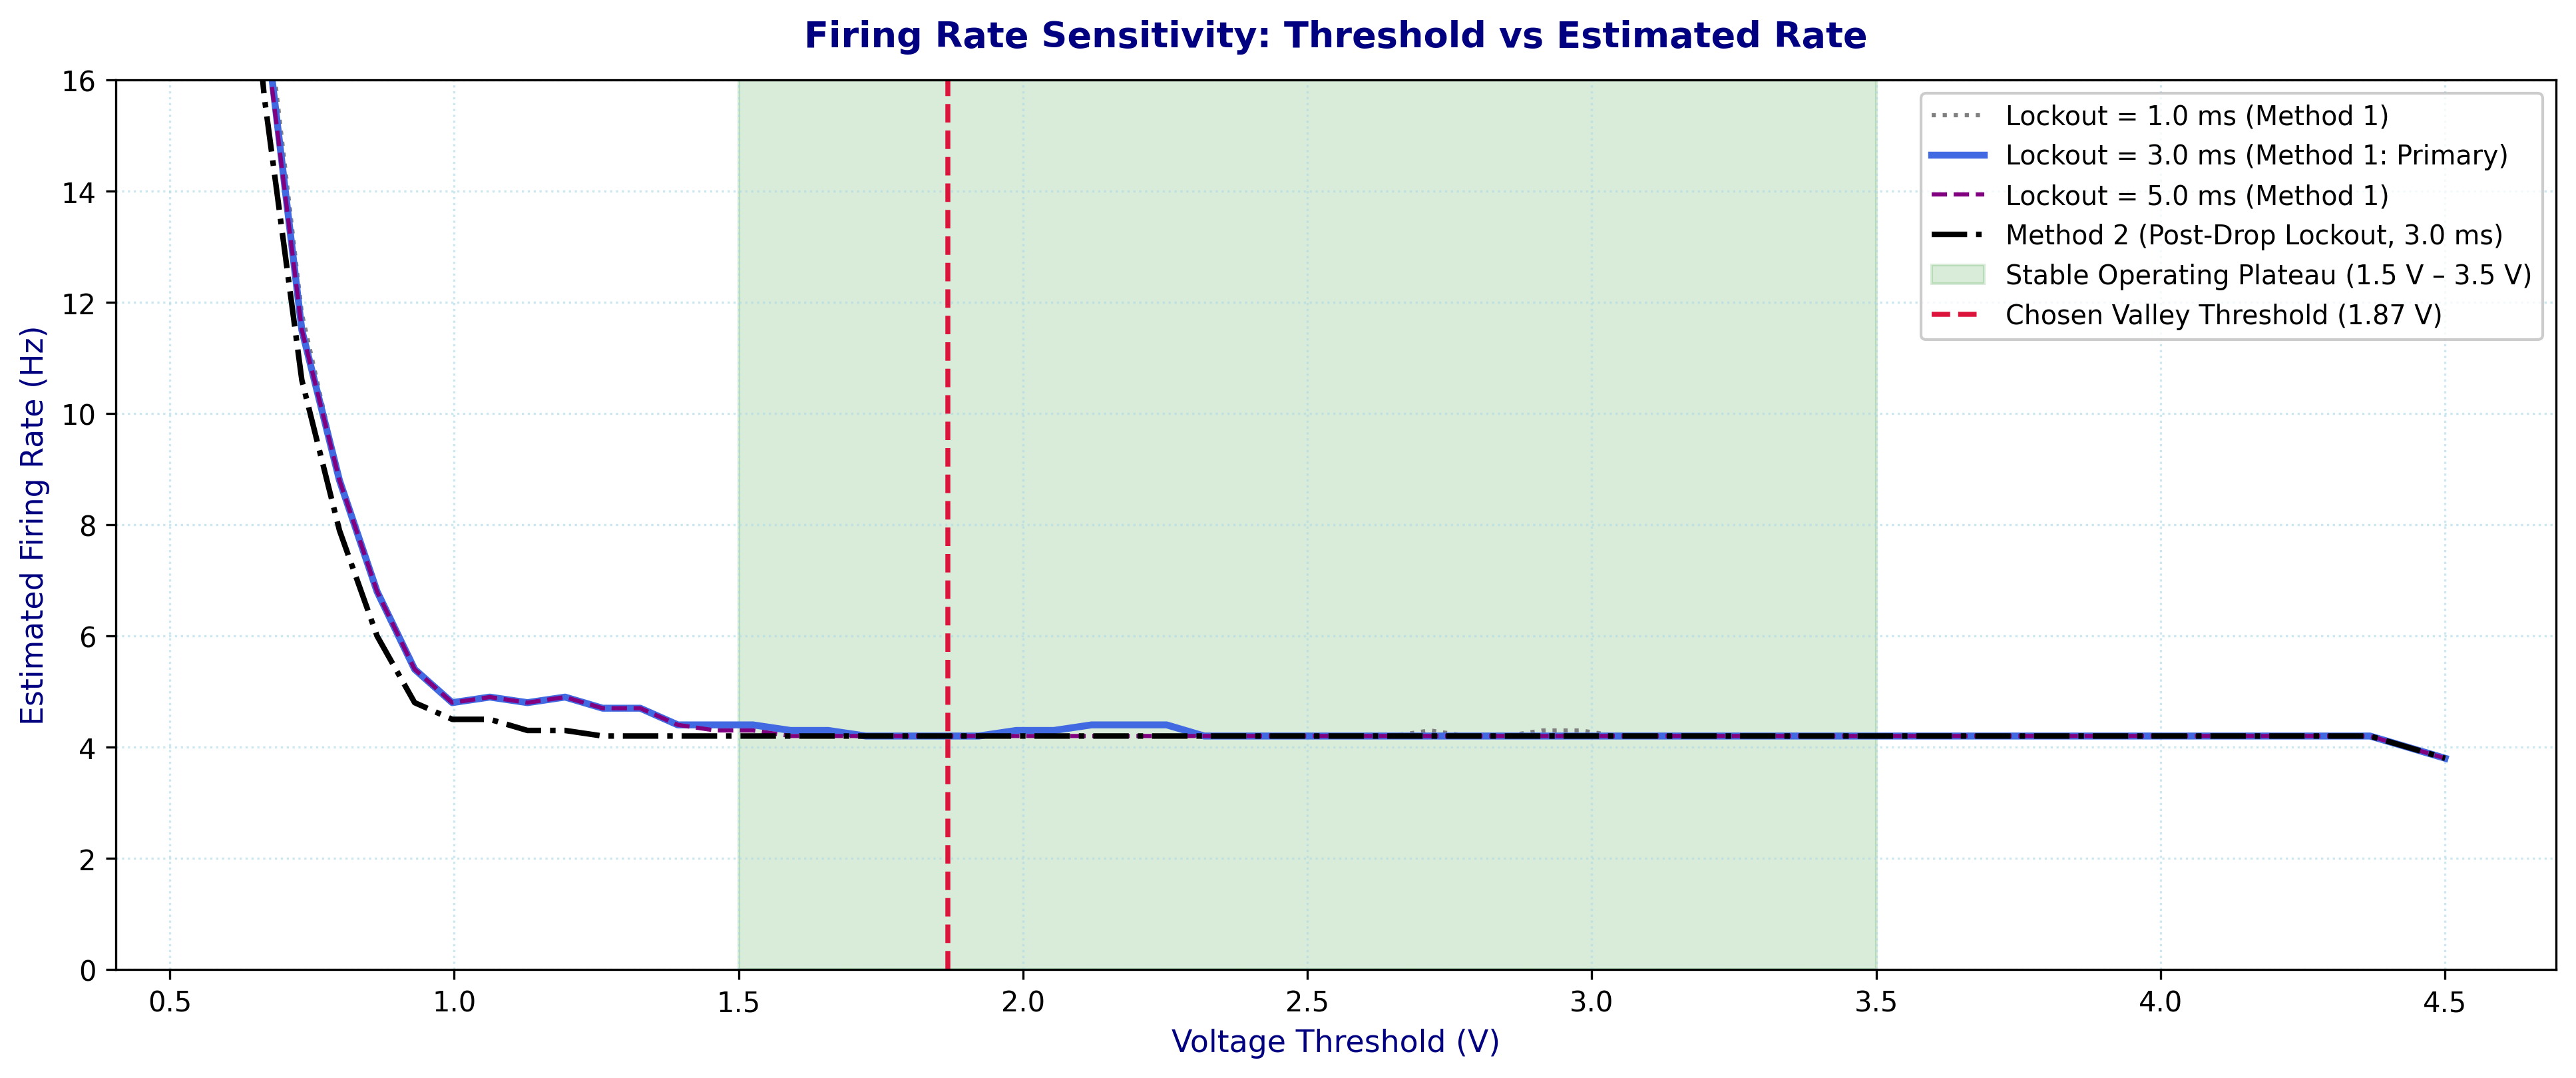

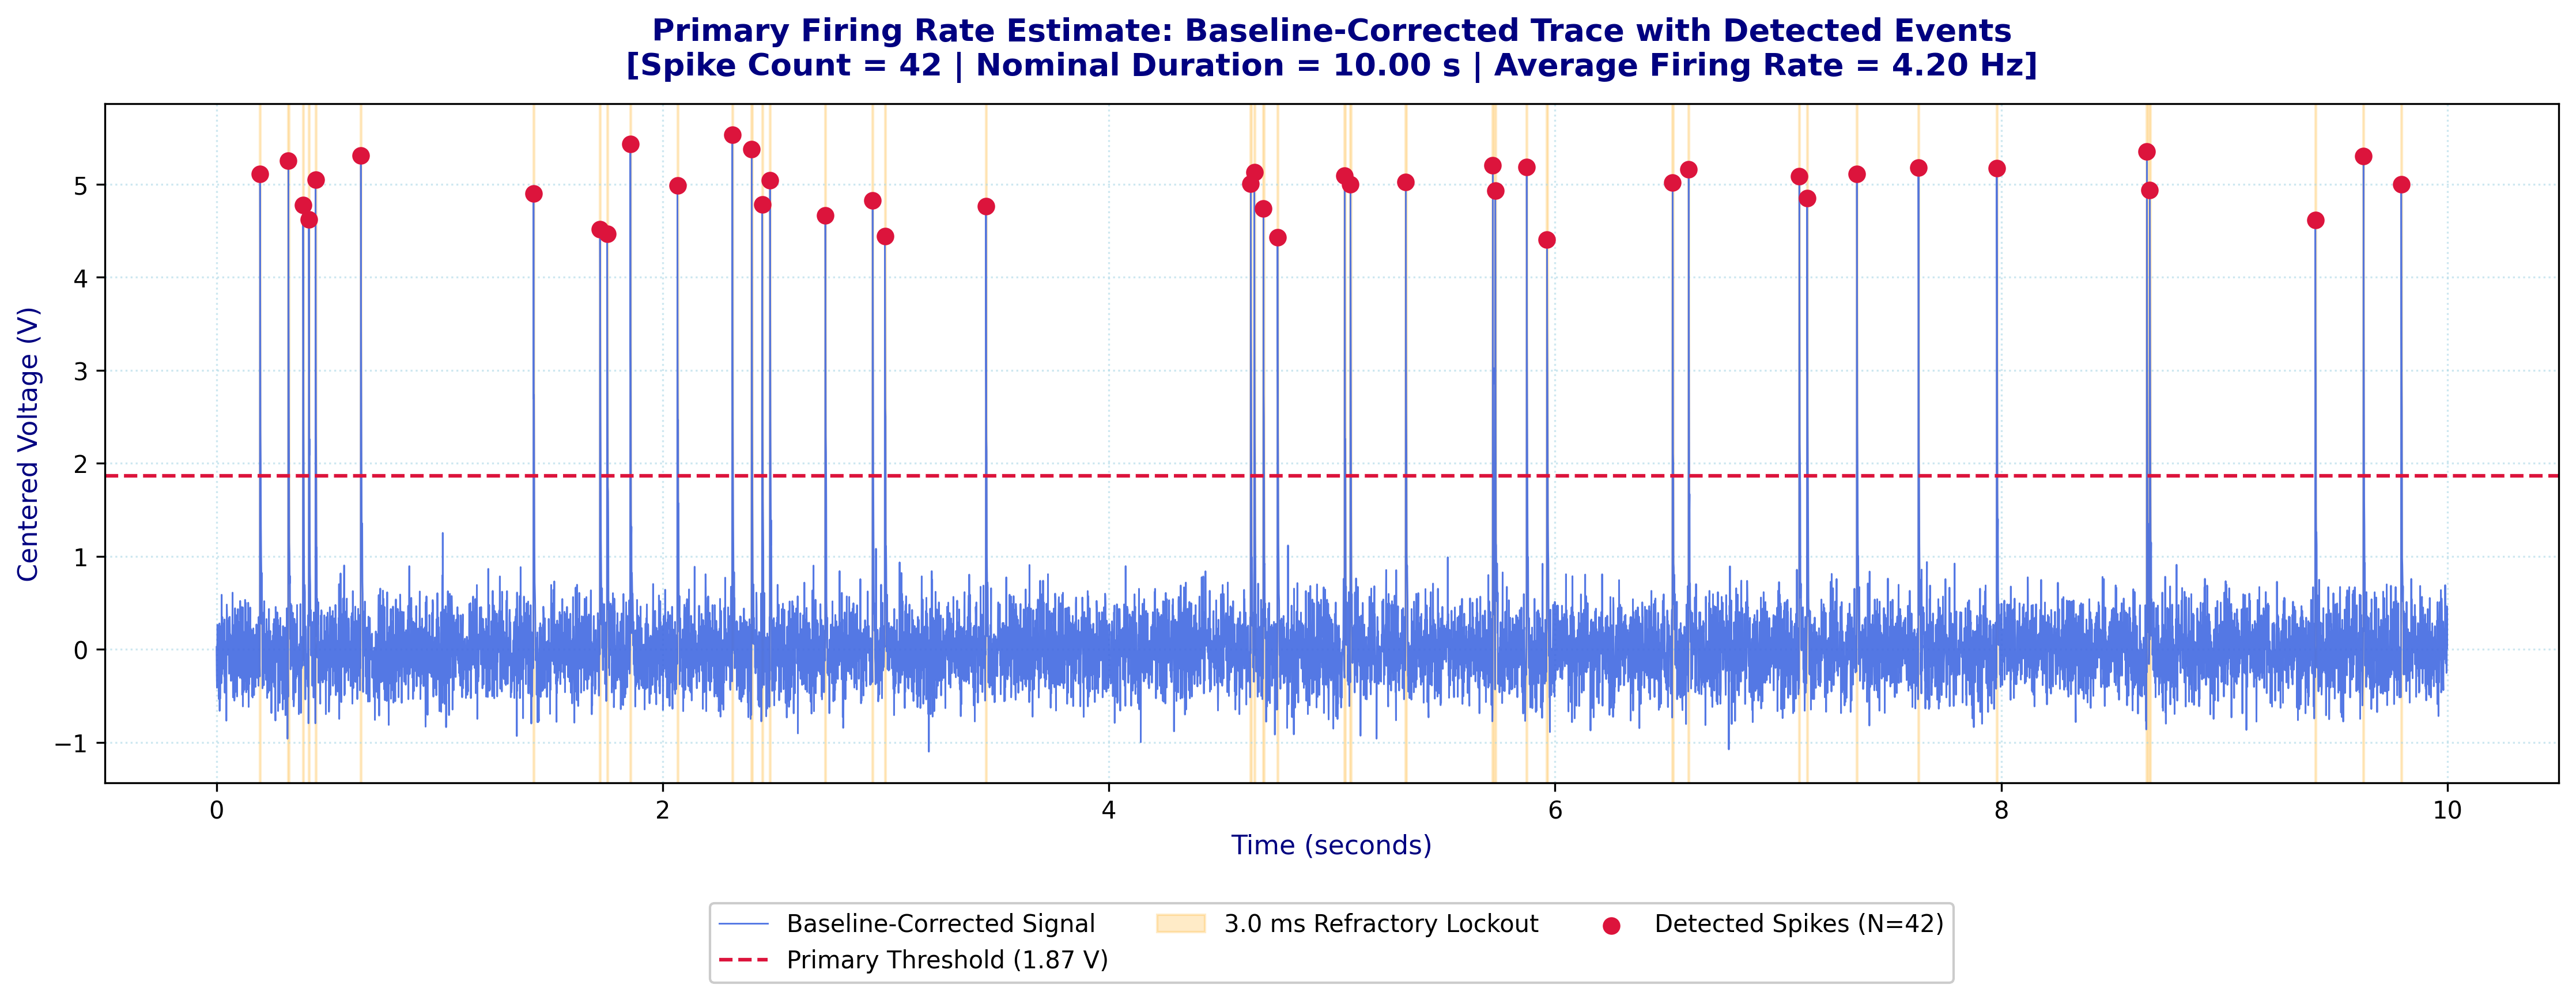

In [36]:
# ==========================================================
# PART 4: Parameter Sensitivity & Stability Evaluation
# ==========================================================

# 1. Primary Firing-Rate Estimate
# ----------------------------------------------------------
# Primary estimate using the Empirical Valley Threshold and 3 ms lockout
primary_indices = m1_indices
primary_times = t[primary_indices]
primary_voltages = signal_centered[primary_indices]
primary_spike_count = len(primary_indices)
primary_firing_rate = primary_spike_count / duration

print("=== 1. PRIMARY FIRING-RATE ESTIMATE ===")
print(f"Total Detected Spikes:       {primary_spike_count}")
print(f"Recording Duration:          {duration:.2f} seconds")
print(f"Primary Firing Rate:         {primary_firing_rate:.2f} Hz\n")


# 2. Parameter Sensitivity Sweep
# ----------------------------------------------------------
threshold_sweep = np.linspace(0.6, 4.5, 60)
lockout_durations_ms = [1.0, 3.0, 5.0]

sweep_m1 = {f"{lock_ms}ms": [] for lock_ms in lockout_durations_ms}
sweep_m2 = []

for th in threshold_sweep:
  # Method 1 (Peak-to-peak lockout)
  for lock_ms in lockout_durations_ms:
    lock_samples = max(1, int((lock_ms / 1000.0) * fs))
    detected = detect_spikes_custom(
        signal_centered, threshold=th, min_dist_samples=lock_samples
    )
    sweep_m1[f"{lock_ms}ms"].append(len(detected) / duration)

  # Method 2 (Post-threshold-drop lockout at 3.0 ms)
  detected_m2, _ = detect_spikes_post_drop(
      signal_centered, threshold=th, lockout_ms=3.0, fs_rate=fs
  )
  sweep_m2.append(len(detected_m2) / duration)


# 3. Figure 1: Parameter Sensitivity Curve
# ----------------------------------------------------------
plt.figure(figsize=(13, 5.5))
plt.plot(
    threshold_sweep,
    sweep_m1["1.0ms"],
    label="Lockout = 1.0 ms (Method 1)",
    color="gray",
    linestyle=":",
    linewidth=1.5,
)
plt.plot(
    threshold_sweep,
    sweep_m1["3.0ms"],
    label="Lockout = 3.0 ms (Method 1: Primary)",
    color="royalblue",
    linewidth=2.5,
)
plt.plot(
    threshold_sweep,
    sweep_m1["5.0ms"],
    label="Lockout = 5.0 ms (Method 1)",
    color="purple",
    linestyle="--",
    linewidth=1.5,
)
plt.plot(
    threshold_sweep,
    sweep_m2,
    label="Method 2 (Post-Drop Lockout, 3.0 ms)",
    color="black",
    linestyle="-.",
    linewidth=2.0,
)

# Highlight the empirical valley stability plateau
plt.axvspan(
    1.5,
    3.5,
    color="green",
    alpha=0.15,
    label="Stable Operating Plateau (1.5 V – 3.5 V)",
)
plt.axvline(
    empirical_threshold,
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label=f"Chosen Valley Threshold ({empirical_threshold:.2f} V)",
)

plt.title(
    "Firing Rate Sensitivity: Threshold vs Estimated Rate",
    fontsize=13,
    fontweight="bold",
    color="navy",
    pad=12,
)
plt.xlabel("Voltage Threshold (V)", fontsize=11, color="navy")
plt.ylabel("Estimated Firing Rate (Hz)", fontsize=11, color="navy")
plt.ylim(0, 16)
plt.grid(True, linestyle=":", alpha=0.6, color="lightblue")
plt.legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="silver",
    fontsize=9.5,
)
plt.tight_layout()
plt.show()


# 4. Figure 2: Primary Detected Events on Voltage Trace
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    t,
    signal_centered,
    color="royalblue",
    linewidth=0.7,
    alpha=0.9,
    label="Baseline-Corrected Signal",
)
ax.axhline(
    empirical_threshold,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Primary Threshold ({empirical_threshold:.2f} V)",
)

# Shading 3.0 ms refractory lockouts
first_shade = True
for st in primary_times:
  ax.axvspan(
      st,
      st + 0.003,
      color="orange",
      alpha=0.22,
      label="3.0 ms Refractory Lockout" if first_shade else "",
  )
  first_shade = False

ax.scatter(
    primary_times,
    primary_voltages,
    color="crimson",
    s=40,
    zorder=5,
    label=f"Detected Spikes (N={primary_spike_count})",
)

ax.set_title(
    f"Primary Firing Rate Estimate: Baseline-Corrected Trace with Detected"
    f" Events\n[Spike Count = {primary_spike_count} | Nominal Duration ="
    f" {duration:.2f} s | Average Firing Rate = {primary_firing_rate:.2f} Hz]",
    fontsize=13,
    fontweight="bold",
    color="navy",
    pad=12,
)
ax.set_xlabel("Time (seconds)", fontsize=11, color="navy")
ax.set_ylabel("Centered Voltage (V)", fontsize=11, color="navy")
ax.grid(True, linestyle=":", alpha=0.6, color="lightblue")
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    frameon=True,
    facecolor="white",
    edgecolor="silver",
    fontsize=10,
)
plt.tight_layout()
plt.show()

In [37]:
import time

# ==========================================================
# Version A: Reference Implementation (Plain Python Loop)
# ==========================================================
def detect_threshold_crossings_loop(signal, threshold):
    """
    Identifies the start index of every contiguous interval
    that rises above the threshold using an explicit Python loop.
    """
    event_start_indices = []
    in_event = False

    for i in range(len(signal)):
        if signal[i] > threshold:
            if not in_event:
                event_start_indices.append(i)
                in_event = True
        else:
            in_event = False

    return np.array(event_start_indices, dtype=int)


# ==========================================================
# Version B: Vectorized NumPy Implementation
# ==========================================================
def detect_threshold_crossings_numpy(signal, threshold):
    """
    Identifies the start index of every contiguous interval
    that rises above the threshold using vectorized Boolean arrays.
    Avoids explicit Python loops over individual samples.
    """
    signal = np.asarray(signal)
    above = signal > threshold

    # An event starts if a sample is above threshold AND the previous sample was not
    starts = above & np.concatenate(([False], ~above[:-1]))

    return np.where(starts)[0]


# ==========================================================
# Evaluation 1: Correctness Check
# ==========================================================
events_loop = detect_threshold_crossings_loop(signal_centered, empirical_threshold)
events_numpy = detect_threshold_crossings_numpy(signal_centered, empirical_threshold)

is_identical = np.array_equal(events_loop, events_numpy)
print("=== EVALUATION 1: CORRECTNESS CHECK ===")
print(f"Events detected by Version A (Loop):  {len(events_loop)}")
print(f"Events detected by Version B (NumPy): {len(events_numpy)}")
print(f"Do both outputs match identically?   {is_identical}\n")


# ==========================================================
# Evaluation 2: Runtime Benchmark (Median Timing)
# ==========================================================
n_repeats = 100
times_loop = []
times_numpy = []

# Benchmark Version A
for _ in range(n_repeats):
    t0 = time.perf_counter()
    _ = detect_threshold_crossings_loop(signal_centered, empirical_threshold)
    t1 = time.perf_counter()
    times_loop.append((t1 - t0) * 1000.0)  # ms

# Benchmark Version B
for _ in range(n_repeats):
    t0 = time.perf_counter()
    _ = detect_threshold_crossings_numpy(signal_centered, empirical_threshold)
    t1 = time.perf_counter()
    times_numpy.append((t1 - t0) * 1000.0)  # ms

med_loop = np.median(times_loop)
med_numpy = np.median(times_numpy)
speedup = med_loop / med_numpy

benchmark_df = pd.DataFrame({
    'Input Size': [len(signal_centered)],
    'Timing Method': [f'Median of {n_repeats} runs (time.perf_counter)'],
    'Version A (Loop) [ms]': [f'{med_loop:.3f} ms'],
    'Version B (NumPy) [ms]': [f'{med_numpy:.3f} ms'],
    'Measured Speedup': [f'{speedup:.1f}x faster']
})

print("=== EVALUATION 2: BENCHMARK TABLE ===")
display(benchmark_df)

=== EVALUATION 1: CORRECTNESS CHECK ===
Events detected by Version A (Loop):  42
Events detected by Version B (NumPy): 42
Do both outputs match identically?   True

=== EVALUATION 2: BENCHMARK TABLE ===


,Input Size,Timing Method,Version A (Loop) [ms],Version B (NumPy) [ms],Measured Speedup
0,10000,Median of 100 runs (time.perf_counter),1.473 ms,0.013 ms,110.4x faster
